# Bank Customer Churn Analysis

## Project Overview

This project analyzes account data for 10,000 customers of a European bank. The dataset includes information such as credit score, account balance, number of products, and whether each customer has churned.

The analysis covers:

- Data cleaning and preprocessing
- Exploratory data analysis (EDA)
- Statistical analysis
- Predictive modeling

## Objectives

This analysis aims to answer the following questions:

- Which attributes are more common among churned customers than retained customers, and can churn be predicted using the available data?
- What does the customer base look like (geography, gender, age, card type)?
- How does account behavior differ among customers in Germany, France, and Spain?
- What distinct customer segments can be identified?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import math

In [ ]:
df = pd.read_csv('Customer-Churn-Records.csv')

data = df.copy()

data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


## Loading Data
#### Making a copy of dataset and performing analysis on it, so original dataset remain unchange.
Important records dataset contain, for analysis include:
- CreditScore
- Geography
- Gender
- Age
- Tenure
- Balance
- NumOfProducts
- HasCrCard
- IsActiveMember
- EstimatedSalary
- Exited
- Complain
- Satisfaction Score
- Card Type
- Point Earned
---

## Data Quality Assessment

- Droping Record that are not neccessary in analysis:
    - Row Number
    - Surname

- Data Summary.
- Handling Missing Values.
- Duplicate Record.
- Memory Optimization.
- Exploring any anomaly detection.


In [4]:
data = data.drop(['RowNumber', 'Surname'], axis= 1)


print(f" Dataset Information ".center(50,"="))
data.info()
print()
print(" Null Values ".center(50, '='))
print(data.isnull().sum())
print()
print(' Duplicate Values in Dataset '.center(50, '='))
print(f"Duplicate data: {data.duplicated().sum()}")
print()
print(f"\nMemory Usage Before Optimization")
before_mem = (df.memory_usage(deep= True).sum() / 1024**2)
print(f'{before_mem:.2f} MB')

============== Dataset Information ===============
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerId          10000 non-null  int64  
 1   CreditScore         10000 non-null  int64  
 2   Geography           10000 non-null  object 
 3   Gender              10000 non-null  object 
 4   Age                 10000 non-null  int64  
 5   Tenure              10000 non-null  int64  
 6   Balance             10000 non-null  float64
 7   NumOfProducts       10000 non-null  int64  
 8   HasCrCard           10000 non-null  int64  
 9   IsActiveMember      10000 non-null  int64  
 10  EstimatedSalary     10000 non-null  float64
 11  Exited              10000 non-null  int64  
 12  Complain            10000 non-null  int64  
 13  Satisfaction Score  10000 non-null  int64  
 14  Card Type           10000 non-null  object 
 15  Poi

## Optimizing Data

In [5]:
int_data = data.select_dtypes('int').columns.tolist()
float_data = data.select_dtypes('float').columns.tolist()
cat_data = ['Geography', 'Gender', 'Card Type']

data[int_data] = data[int_data].astype('int32')
data[cat_data] = data[cat_data].astype('category')
data[float_data] = data[float_data].astype('float32')

print(f" Updated Dataset Information ".center(50,"="))
data.info()

after_mem = (data.memory_usage(deep= True).sum() / (1024**2))
print(f"\nMemory Usage After Optimization")
print(f'{after_mem:.2f} MB')
print(f'Total Memory reduction: {(((before_mem-after_mem) * 100)/before_mem):.2f}%')

========== Updated Dataset Information ===========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   CustomerId          10000 non-null  int32   
 1   CreditScore         10000 non-null  int32   
 2   Geography           10000 non-null  category
 3   Gender              10000 non-null  category
 4   Age                 10000 non-null  int32   
 5   Tenure              10000 non-null  int32   
 6   Balance             10000 non-null  float32 
 7   NumOfProducts       10000 non-null  int32   
 8   HasCrCard           10000 non-null  int32   
 9   IsActiveMember      10000 non-null  int32   
 10  EstimatedSalary     10000 non-null  float32 
 11  Exited              10000 non-null  int32   
 12  Complain            10000 non-null  int32   
 13  Satisfaction Score  10000 non-null  int32   
 14  Card Type           10000 non-null  

## Data Statistical Summary

In [6]:
data.describe(include= 'all')

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
count,1.000000e+04,10000.000000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000,10000.000000
unique,NaN,NaN,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN
top,NaN,NaN,France,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DIAMOND,NaN
freq,NaN,NaN,5014,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2507,NaN
mean,1.569094e+07,650.528800,NaN,NaN,38.921800,5.012800,76485.890625,1.530200,0.70550,0.515100,100090.234375,0.203800,0.204400,3.013800,NaN,606.515100
std,7.193619e+04,96.653299,NaN,NaN,10.487806,2.892174,62398.953125,0.581654,0.45584,0.499797,57510.468750,0.402842,0.403283,1.405919,NaN,225.924839
min,1.556570e+07,350.000000,NaN,NaN,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,NaN,119.000000
25%,1.562853e+07,584.000000,NaN,NaN,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.109375,0.000000,0.000000,2.000000,NaN,410.000000
50%,1.569074e+07,652.000000,NaN,NaN,37.000000,5.000000,97198.539062,1.000000,1.00000,1.000000,100193.914062,0.000000,0.000000,3.000000,NaN,605.000000
75%,1.575323e+07,718.000000,NaN,NaN,44.000000,7.000000,127644.238281,2.000000,1.00000,1.000000,149388.253906,0.000000,0.000000,4.000000,NaN,801.000000


We can check from statistcal summary that:
- Minmum Balance value is 0 Q1 is 0 too.
- Minimum EstimatedSalary is 11.58 but Q1 is 51,002.

find out number of customer who have balance/estimated salary lower than Ist quantilie.

In [7]:
low_balance = data[data['Balance'] <= 50000]
print(f'Number of customer with Balance lower than 50000: {low_balance.shape[0]:,}')

low_estimatedsalary = data[data['EstimatedSalary'] <= 50000]
print(f'Number of customer with low estimated Salary: {low_estimatedsalary.shape[0]:,}')

Number of customer with Balance lower than 50000: 3,692
Number of customer with low estimated Salary: 2,453


## Data Cleaning & Processing Summary

| Action | Count / Result | Details |
|:--|:--:|:--|
| Balance ≤ 50,000 | 3,692 | Customers in this balance range |
| Estimated salary ≤ 50,000 | 2,453 | Customers in this salary range |
| Null values | 0 | No missing values found |
| Duplicate rows | 0 | No duplicates found |
| Columns dropped | 2 | _RowNumber_ and _Surname_ |
| Memory reduction | 80%+ | Downcast _int64_ to _int32_ and _float64_ to _float32_; converted text columns to the _category_ data type |

## EDA: Feature Engineering

- Create new features with the *int8* data type where appropriate.
- Bin the following columns using the specified strategies:

| Column | Binning strategy |
|:--|:--|
| _EstimatedSalary_ | Use quantiles from _data.describe()_ |
| _CreditScore_ | Use standard credit-score ranges |
| _Age_ | Use quantiles from _data.describe()_ |
| _Balance_ | Create bins in increments of 50,000 |
| _Tenure_ | Use quantiles from _data.describe()_ |

In [8]:
salary_labels = ['0-50K', '50K-100K', '100K-150K', '150K+']
data['EstimatedSalary_bin'] = pd.qcut(data['EstimatedSalary'], 4, labels= salary_labels).astype('category')
data['EstimatedSalary_encoded'] = pd.qcut(data['EstimatedSalary'], 4, labels= [1,2,3,4]).astype('int8')

credit_labels = ['300-589', '590-670', '671-739', '740-850']
data['CreditScore_range'] = pd.cut(data['CreditScore'], bins= [300, 589, 670, 739, 850], labels= credit_labels).astype('category')
data['CreditScore_encoded'] = pd.cut(data['CreditScore'], bins= [300, 589, 670, 739, 850], labels= [1,2,3,4]).astype('int8')

age_labels = ['18-32', '32-37', '37-44', '45+']
data['Age_range'] = pd.qcut(data['Age'], 4, labels= age_labels).astype('category')

balance_labels = ['0-50K', '50K-100K', '100K-150K', '150K+']
data['Balance_bin'] = pd.cut(data['Balance'], bins= [0, 50000, 100000, 150000, data['Balance'].max()], labels= balance_labels, include_lowest= True).astype('category')
data["Balance_encoded"] = pd.cut(data['Balance'], bins= [0, 50000, 100000, 150000, data['Balance'].max()], labels= [1, 2, 3, 4], include_lowest= True).astype('int8')

data['Tenure_range'] = pd.qcut(data['Tenure'], 4, labels= ['0-3', '3-5', '5-7', '7+']).astype('category')
data['Tenure_encoded'] = pd.qcut(data['Tenure'], 4, labels= [1,2,3,4]).astype('int8')

data['Point_Earned_bin'] = pd.cut(data['Point Earned'], bins= [100, 410, 650, 801, data['Point Earned'].max()], labels= ['100-400', '400-600', '600-800', '800+'], include_lowest= True).astype('category')
data['IsActiveMember_label'] = data['IsActiveMember'].map({1:'Yes', 0:'No'}).astype('category')
data['Exited_label'] = data['Exited'].map({1:'Yes', 0:'No'}).astype('category')
data['HasCrCard_label'] = data['HasCrCard'].map({1:'Yes', 0:'No'}).astype('category')

sat_bin = ['Very Dissatisfied', 'Dissatisfied', 'Neutral', 'Satisfied', 'Very Satisfied']
data['Satisfaction Score'] = pd.cut(data['Satisfaction Score'], bins= [0,1,2,3,4,5], labels= sat_bin).astype('category')

data['Geography_encoded'] = data['Geography'].cat.codes
data['Gender_encoded'] = data['Gender'].cat.codes

Using manual encoding of Categorical data to make is Ordinal data

In [9]:
data.info()

final_mem = (data.memory_usage(deep= True).sum() / (1024**2))
print(f"\nMemory Usage After Feature Engineering")
print(f'{final_mem:.2f} MB')
print(f'Memory increment: {(((final_mem-after_mem) * 100)/after_mem):.2f}%')
print(f'Memory Lower Compared to Original: {(((before_mem-final_mem) * 100)/before_mem):.2f}%')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   CustomerId               10000 non-null  int32   
 1   CreditScore              10000 non-null  int32   
 2   Geography                10000 non-null  category
 3   Gender                   10000 non-null  category
 4   Age                      10000 non-null  int32   
 5   Tenure                   10000 non-null  int32   
 6   Balance                  10000 non-null  float32 
 7   NumOfProducts            10000 non-null  int32   
 8   HasCrCard                10000 non-null  int32   
 9   IsActiveMember           10000 non-null  int32   
 10  EstimatedSalary          10000 non-null  float32 
 11  Exited                   10000 non-null  int32   
 12  Complain                 10000 non-null  int32   
 13  Satisfaction Score       10000 non-null  category
 14  Card Ty

### Correlation Heatmap

Text(0.5, 1.0, 'Heatmap Correlation')

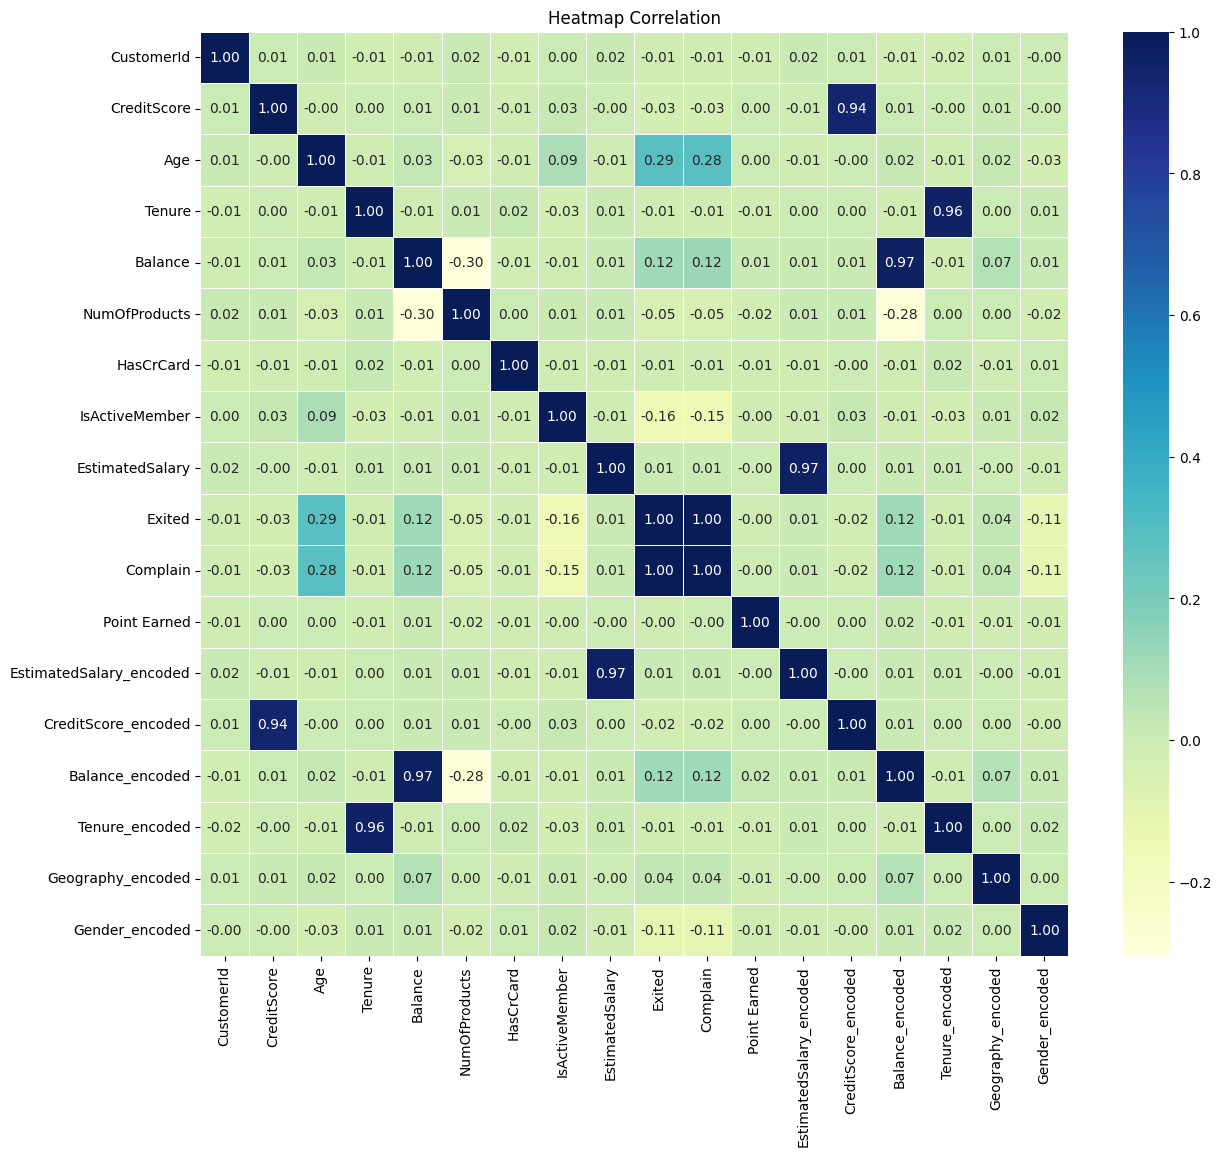

In [10]:
correlation_data = data.select_dtypes([np.number])

correlation_matrix = correlation_data.corr()
plt.figure(figsize= (14,12))
sns.heatmap(correlation_matrix, cmap= 'YlGnBu', annot= True, linewidths= 0.5, fmt= '.2f')
plt.title('Heatmap Correlation')

In [11]:
data = data.drop('Complain', axis= 'columns')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   CustomerId               10000 non-null  int32   
 1   CreditScore              10000 non-null  int32   
 2   Geography                10000 non-null  category
 3   Gender                   10000 non-null  category
 4   Age                      10000 non-null  int32   
 5   Tenure                   10000 non-null  int32   
 6   Balance                  10000 non-null  float32 
 7   NumOfProducts            10000 non-null  int32   
 8   HasCrCard                10000 non-null  int32   
 9   IsActiveMember           10000 non-null  int32   
 10  EstimatedSalary          10000 non-null  float32 
 11  Exited                   10000 non-null  int32   
 12  Satisfaction Score       10000 non-null  category
 13  Card Type                10000 non-null  category
 14  Point E

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif

X = data.select_dtypes(['number']).drop(['CreditScore','Balance', 'EstimatedSalary','Exited','CustomerId'], axis= 1)
y = data['Exited']

selector = SelectKBest(score_func= f_classif, k= 5)

X_selected = selector.fit_transform(X, y)

# Display features scores
print("Feature scores:")
for feature, score in zip(X.columns, selector.scores_):
    print(f"{feature}: {score:.3f}")


selected_features = X.columns[selector.get_support()].tolist()
print("\nSelected top 5 features:", selected_features)

Feature scores:
Age: 885.880
Tenure: 1.864
NumOfProducts: 22.718
HasCrCard: 0.488
IsActiveMember: 250.547
Point Earned: 0.216
EstimatedSalary_encoded: 2.019
CreditScore_encoded: 3.913
Balance_encoded: 134.435
Tenure_encoded: 1.298
Geography_encoded: 12.768
Gender_encoded: 114.193

Selected top 5 features: ['Age', 'NumOfProducts', 'IsActiveMember', 'Balance_encoded', 'Gender_encoded']


- **_Complain_ and _Exited_ are perfectly correlated.** This may indicate target leakage, so dropping _Complain_ is a better choice. Since we don’t know whether the complaint was recorded before or after the customer exited.
- Other notable correlations:
  - _Gender_encoded_ is negatively correlated with _Exited_ 
  - _NumOfProducts_ and _Balance_ are negatively correlated.
  - _Age_ and _Exited_ are positively correlated.
  - _IsActiveMember_ and _Exited_ are negatively correlated.
  - _Balance_ and _Exited_ are positively correlated.


- Use SelectKBest with f_classif to check wheather we have selected statistically correlated feature.
    - Top 5 features are:
        - Age
        - NumOfProducts
        - IsActiveMember
        - Balance_encoded
        - Gender_encoded
    - Matching with the Correlation matrix and  heatmap

- Conduct focuesd EDA on strong correlation variable with Exited.
  - Gender
  - NumOfProducts
  - Age
  - Balance
  - IsActiveMember
- Next, we’ll use histograms and box plots to examine the feature distributions, then create bar charts to explore how the number of products relates to churn across other key variables.

## Data Distribution Using Histograms and Box Plots

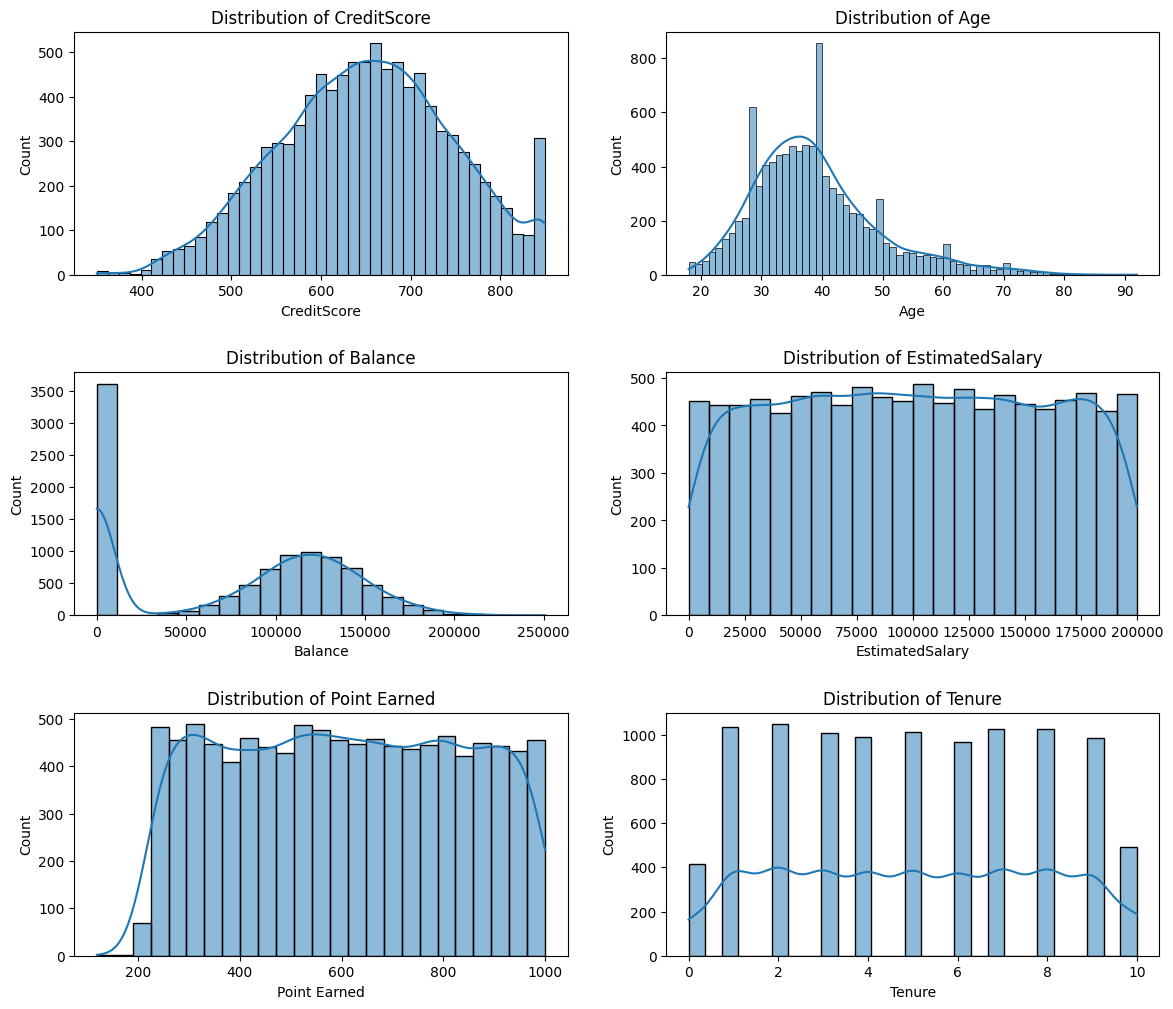

In [13]:
features_to_plot = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary','Point Earned', 'Tenure']
col = 2
row = int(math.ceil(len(features_to_plot)/ col))

fig, ax = plt.subplots(row,col, figsize=(14,12))
ax_flat = ax.flatten()
fig.subplots_adjust(hspace= 0.4)
for i, feature in enumerate(features_to_plot):
    sns.histplot(data= data, x= feature, kde= True, edgecolor= 'black', ax= ax_flat[i]);
    ax_flat[i].set_title(f'Distribution of {feature}');

for j in range(i +1,len(ax_flat)):
    fig.delaxes(ax_flat[j])

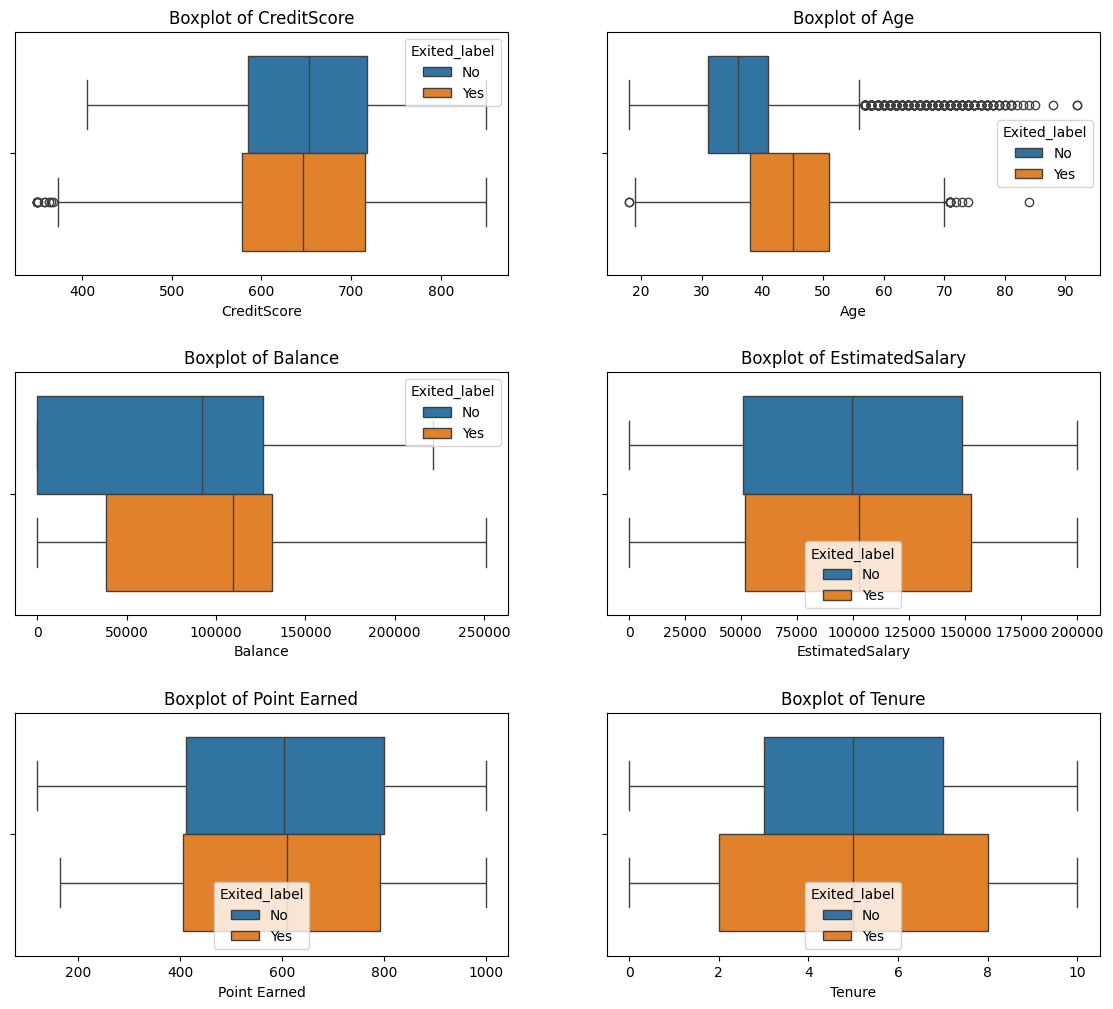

In [14]:
col = 2
row = int(math.ceil(len(features_to_plot)/ col))

fig, ax = plt.subplots(row,col, figsize=(14,12))
fig.set_label('Box Plot')
ax_flat = ax.flatten()
fig.subplots_adjust(hspace= 0.4)
for i, feature in enumerate(features_to_plot):
    sns.boxplot(data= data, x= feature, ax= ax_flat[i],hue= data['Exited_label']);
    ax_flat[i].set_title(f'Boxplot of {feature}');

for j in range(i +1,len(ax_flat)):
    fig.delaxes(ax_flat[j])

- **Outlier handling:** Retain outliers during the initial analysis, as extreme values may reflect genuine customer behavior that influences churn. Investigate their impact before deciding whether to remove or transform them.

Table with Geography Gender:
  Geography  Gender  customer_count  Churn  Churn_pct (%)
0    France  Female            2261    460          20.34
1    France    Male            2753    351          12.75
2   Germany  Female            1193    448          37.55
3   Germany    Male            1316    366          27.81
4     Spain  Female            1089    231          21.21
5     Spain    Male            1388    182          13.11

Table with Geography vs NumOfProducts:
   Geography  NumOfProducts  customer_count  Churn  Churn_pct (%)
0     France              1            2514    564          22.43
1     France              2            2367    136           5.75
2     France              3             104     82          78.85
3     France              4              29     29         100.00
4    Germany              1            1349    578          42.85
5    Germany              2            1040    126          12.12
6    Germany              3              96     86          89.

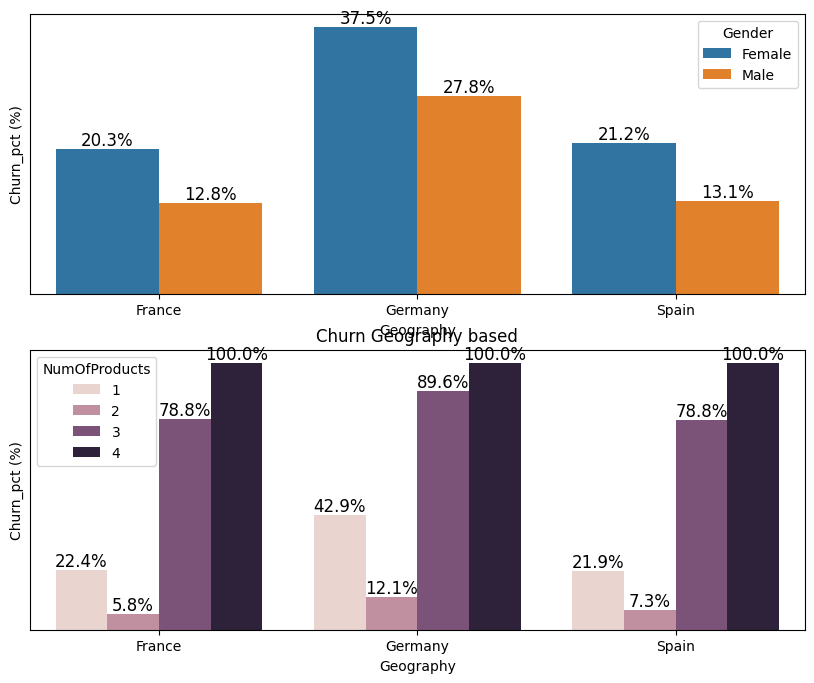

In [15]:
def churn_rate(dataset, col_name):
    """
    Return Group by table, with Gender, Customer Count and Exited.
    Take 2 Argument dataset, and feature name use to groupby as str.
    Plot Bar chart.
        Label on Bar edge.
        hue= Gender.
        Y-ticks are off
    """
    x = dataset.groupby([str(col_name),'Gender'], observed= False).agg(customer_count= ('CustomerId', 'count'),Churn= ('Exited', 'sum'))
    x['Churn_pct (%)'] = ((x['Churn'] * 100)/x['customer_count']).round(2)
    x = x.reset_index()

    y = dataset.groupby([str(col_name), 'NumOfProducts'], observed= False).agg(customer_count= ('CustomerId', 'count'),Churn= ('Exited', 'sum'))
    y['Churn_pct (%)'] = ((y['Churn'] * 100)/y['customer_count']).round(2)
    y = y.reset_index()
    
    fig, ax = plt.subplots(2,1, figsize= (10,8))
    sns.barplot(data= x, x= str(col_name), y= 'Churn_pct (%)', hue= 'Gender', ax= ax[0])
    sns.barplot(data= y, x= str(col_name), y= 'Churn_pct (%)', hue= 'NumOfProducts', ax= ax[1])
    plt.title(f'Churn {str(col_name)} based');
    ax[0].set_yticks([])
    ax[1].set_yticks([])
    for container in ax[0].containers:
        ax[0].bar_label(container, fmt='%1.1f%%', label_type='edge', fontsize=12)
    for container in ax[1].containers:
        ax[1].bar_label(container, fmt='%1.1f%%', label_type='edge', fontsize=12)
    print(f'Table with {str(col_name)} Gender:\n{x}\n\nTable with {str(col_name)} vs NumOfProducts:\n{y}')
    return [x,y]


non_zero_balance = data[data['Balance'] != 0]
geography_based = churn_rate(data, 'Geography')


### Churn by Geography and Gender
- Germany has the highest churn rate among the three countries.
- In each country, female customers have a higher churn rate than male customers.
- Customers with 4 products have a 100% churn rate, followed by customers with 3 products, who also show relatively high churn.
- Customers with 2 products have the lowest churn rate, followed by those with 1 product.

## Exploring Customers with a Non-Zero Balance

- Approximately 3,600 customers have a zero balance. We’ll set them aside for this analysis and focus on customers with a balance greater than zero (`non_zero_balance`).
- For some analyses, we may include both groups, depending on the question—for example, when comparing churn across geographies.

Table with IsActiveMember_label Gender:
  IsActiveMember_label  Gender  customer_count  Churn  Churn_pct (%)
0                   No  Female            1454    536          36.86
1                   No    Male            1651    447          27.07
2                  Yes  Female            1435    313          21.81
3                  Yes    Male            1843    242          13.13

Table with IsActiveMember_label vs NumOfProducts:
  IsActiveMember_label  NumOfProducts  customer_count  Churn  Churn_pct (%)
0                   No              1            2048    701          34.23
1                   No              2             929    158          17.01
2                   No              3             103     99          96.12
3                   No              4              25     25         100.00
4                  Yes              1            2131    370          17.36
5                  Yes              2            1061    105           9.90
6                  Yes          

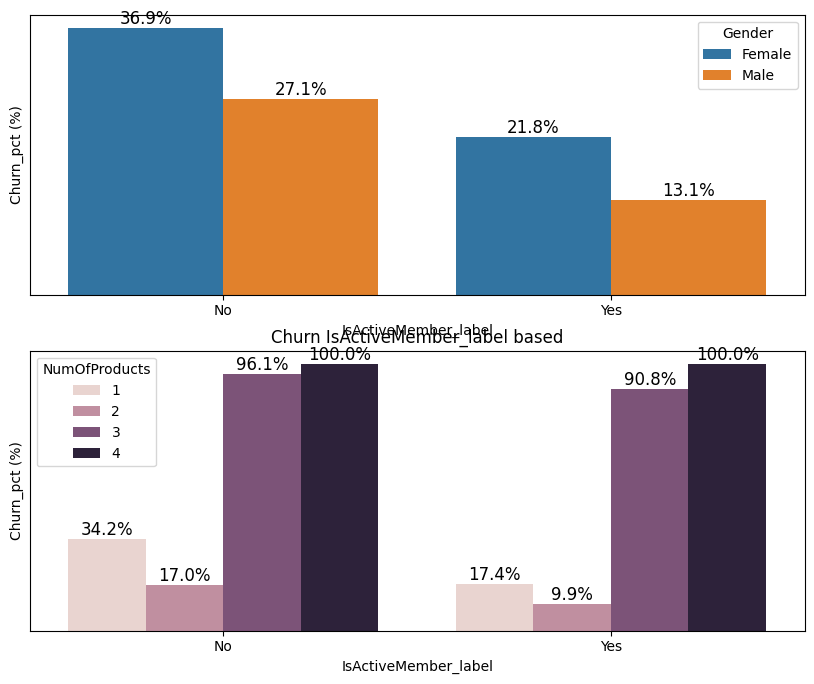

In [16]:
active_mem_base = churn_rate(dataset= non_zero_balance, col_name= 'IsActiveMember_label')

- **Active membership does not change the overall pattern:** Customers with 3 or 4 products have the highest churn rates, even among active members.
- Customers with 2 products have the lowest churn rate, including among inactive members.

Table with Balance_bin Gender:
  Balance_bin  Gender  customer_count  Churn  Churn_pct (%)
0       0-50K  Female            1697    310          18.27
1       0-50K    Male            1995    216          10.83
2    50K-100K  Female             698    176          25.21
3    50K-100K    Male             811    125          15.41
4   100K-150K  Female            1724    533          30.92
5   100K-150K    Male            2106    454          21.56
6       150K+  Female             424    120          28.30
7       150K+    Male             545    104          19.08

Table with Balance_bin vs NumOfProducts:
   Balance_bin  NumOfProducts  customer_count  Churn  Churn_pct (%)
0        0-50K              1             954    355          37.21
1        0-50K              2            2620     90           3.44
2        0-50K              3             103     66          64.08
3        0-50K              4              15     15         100.00
4     50K-100K              1             973  

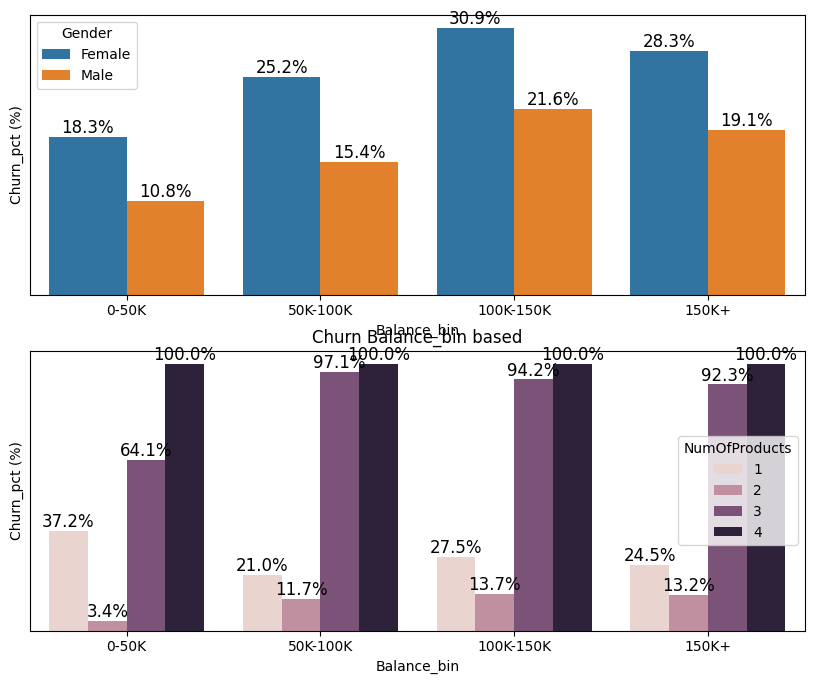

In [17]:
Balance_churn = churn_rate(dataset=data, col_name= 'Balance_bin')

- **Interesting pattern:** Customers with balances of 0–50K have the lowest churn rates when they hold 2 or 3 products. This pattern may be influenced by the inclusion of zero-balance customers.
- In other balance groups, churn is higher among customers with 3 products, while customers with 4 products show a 100% churn rate.
- Among customers with one product, the 0–50K balance group has the highest churn rate.

Table with Age_range Gender:
  Age_range  Gender  customer_count  Churn  Churn_pct (%)
0     18-32  Female             762     95          12.47
1     18-32    Male             958     67           6.99
2     32-37  Female             612    107          17.48
3     32-37    Male             829     80           9.65
4     37-44  Female             746    210          28.15
5     37-44    Male             903    196          21.71
6       45+  Female             769    437          56.83
7       45+    Male             804    346          43.03

Table with Age_range vs NumOfProducts:
   Age_range  NumOfProducts  customer_count  Churn  Churn_pct (%)
0      18-32              1            1114    112          10.05
1      18-32              2             579     28           4.84
2      18-32              3              22     17          77.27
3      18-32              4               5      5         100.00
4      32-37              1             906    127          14.02
5      32-37 

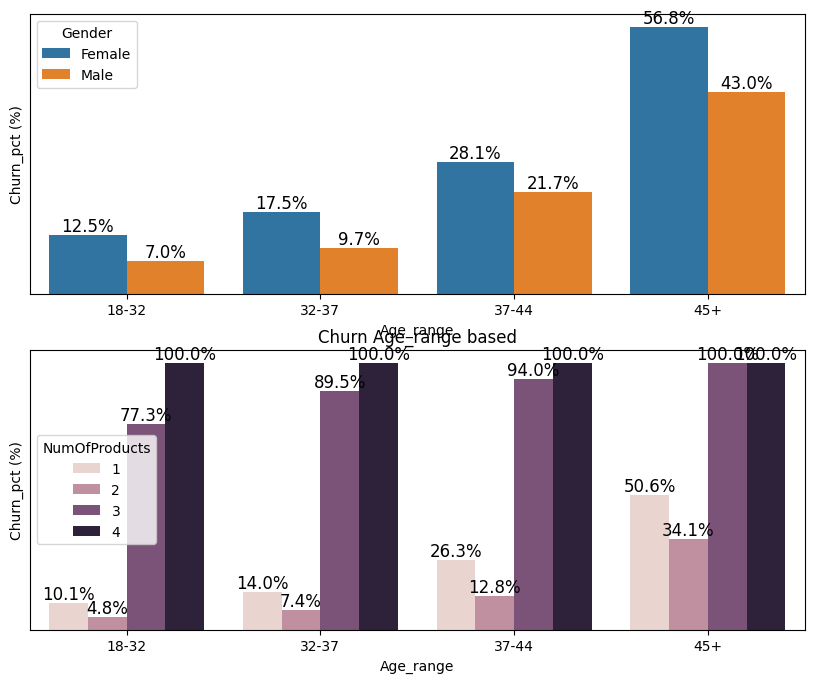

In [18]:
age_churn = churn_rate(dataset= non_zero_balance, col_name= 'Age_range')

Insight: Customers aged 45+ have the highest churn rate across all product counts. In contrast, churn among younger age groups 2 Product lowest, 3+ product jump Sharply. Even after purchasing three products, customers under 45 have a comparatively lower churn rate than those aged 45 and older.

## Exploring Customer with Zero Balance
### We’ll explore customer with zero balance group’s characteristics and behavior through further EDA.
- Approximately 3,600 customers have a balance of zero.

In [19]:
zero_balance = data[data['Balance'] == 0]
zero_balance.head()

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,...,Balance_bin,Balance_encoded,Tenure_range,Tenure_encoded,Point_Earned_bin,IsActiveMember_label,Exited_label,HasCrCard_label,Geography_encoded,Gender_encoded
0,15634602,619,France,Female,42,2,0.0,1,1,1,...,0-50K,1,0-3,1,400-600,Yes,Yes,Yes,0,0
3,15701354,699,France,Female,39,1,0.0,2,0,0,...,0-50K,1,0-3,1,100-400,No,No,No,0,0
6,15592531,822,France,Male,50,7,0.0,2,1,1,...,0-50K,1,5-7,3,100-400,Yes,No,Yes,0,1
11,15737173,497,Spain,Male,24,3,0.0,2,1,0,...,0-50K,1,0-3,1,100-400,No,No,Yes,2,1
12,15632264,476,France,Female,34,10,0.0,2,1,0,...,0-50K,1,7+,4,100-400,No,No,Yes,0,0


Table with Age_range Gender:
  Age_range  Gender  customer_count  Churn  Churn_pct (%)
0     18-32  Female             484     32           6.61
1     18-32    Male             586     19           3.24
2     32-37  Female             368     30           8.15
3     32-37    Male             488     32           6.56
4     37-44  Female             422     78          18.48
5     37-44    Male             502     48           9.56
6       45+  Female             380    150          39.47
7       45+    Male             387    111          28.68

Table with Age_range vs NumOfProducts:
   Age_range  NumOfProducts  customer_count  Churn  Churn_pct (%)
0      18-32              1             197     31          15.74
1      18-32              2             851     12           1.41
2      18-32              3              21      7          33.33
3      18-32              4               1      1         100.00
4      32-37              1             197     46          23.35
5      32-37 

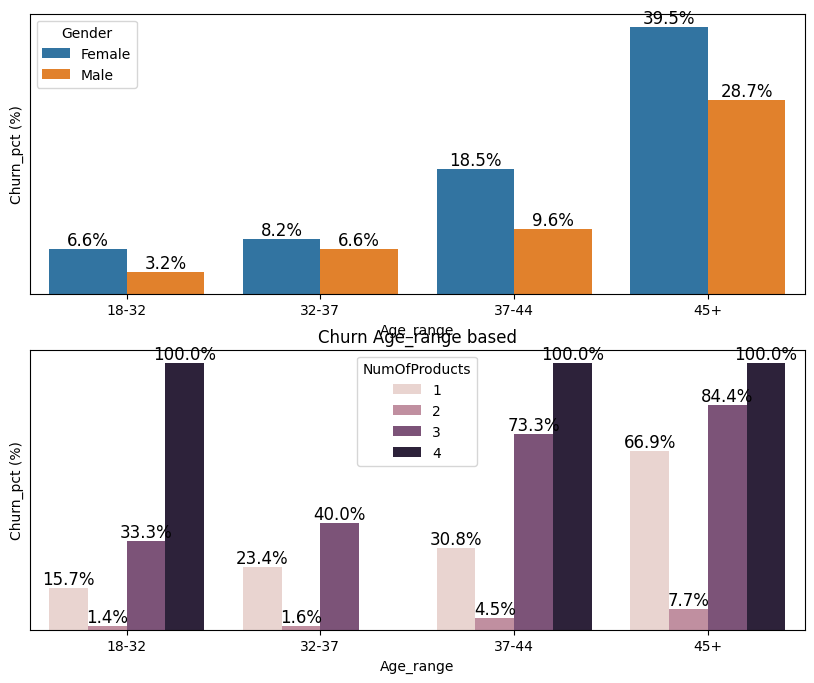

In [20]:
age_base = churn_rate(dataset= zero_balance, col_name= 'Age_range')

- Among zero-balance customers, young adults have a lower churn rate, while customers aged 45+ have a higher churn rate.
- Customers with 2 products have the lowest and 3+ product jump sharply.
- These patterns are similar to those observed among customers with non-zero balances.

Table with IsActiveMember_label Gender:
  IsActiveMember_label  Gender  customer_count  Churn  Churn_pct (%)
0                   No  Female             805    189          23.48
1                   No    Male             939    131          13.95
2                  Yes  Female             849    101          11.90
3                  Yes    Male            1024     79           7.71

Table with IsActiveMember_label vs NumOfProducts:
  IsActiveMember_label  NumOfProducts  customer_count  Churn  Churn_pct (%)
0                   No              1             473    223          47.15
1                   No              2            1215     55           4.53
2                   No              3              50     36          72.00
3                   No              4               6      6         100.00
4                  Yes              1             432    115          26.62
5                  Yes              2            1385     31           2.24
6                  Yes          

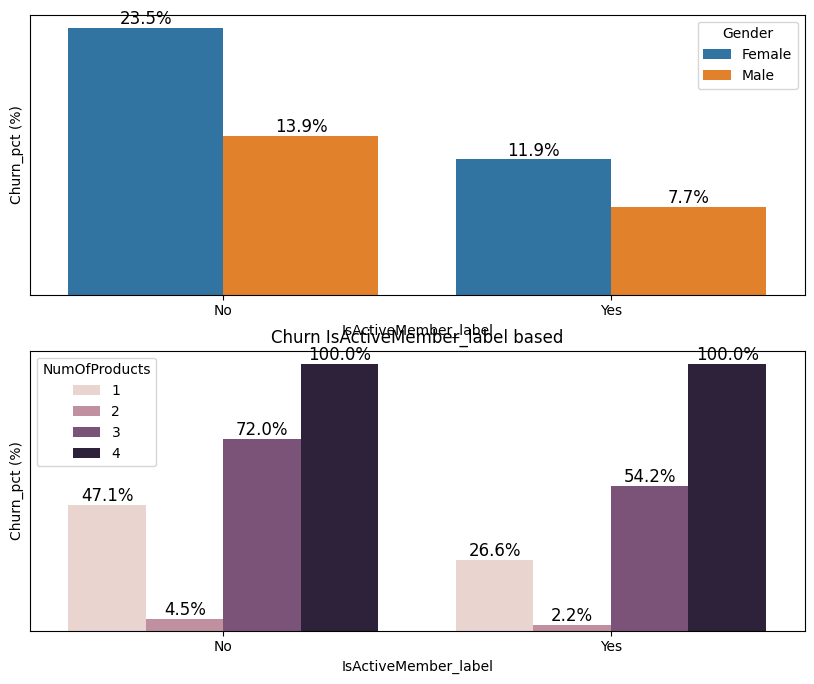

In [21]:
zero_balance_active = churn_rate(dataset= zero_balance, col_name= 'IsActiveMember_label')

- Among customers with three products, active members have a lower churn rate than inactive members.
- The churn rate for inactive members in range of 1.3–2 times higher.

Table with Point_Earned_bin Gender:
  Point_Earned_bin  Gender  customer_count  Churn  Churn_pct (%)
0          100-400  Female             393     81          20.61
1          100-400    Male             519     61          11.75
2          400-600  Female             532     89          16.73
3          400-600    Male             618     70          11.33
4          600-800  Female             312     55          17.63
5          600-800    Male             370     38          10.27
6             800+  Female             417     65          15.59
7             800+    Male             456     41           8.99

Table with Point_Earned_bin vs NumOfProducts:
   Point_Earned_bin  NumOfProducts  customer_count  Churn  Churn_pct (%)
0           100-400              1             218     92          42.20
1           100-400              2             660     26           3.94
2           100-400              3              27     17          62.96
3           100-400              4      

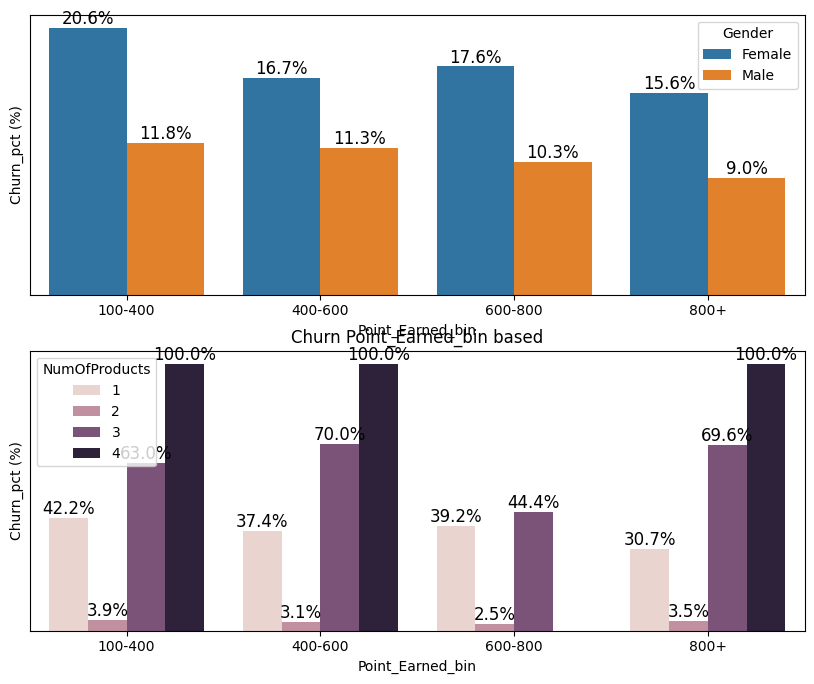

In [22]:
zero_balance_point_earned = churn_rate(dataset= zero_balance, col_name= 'Point_Earned_bin')

- Customers with more points earned tend to have a slightly lower churn rate, though the difference is modest.
- The pattern by product count remains consistent: customers with 3 or 4 products show higher churn rates.

## Overall Churn Rate

  Exited_label  customer_count  Churn_pct (%)
0           No            3117          86.18
1          Yes             500          13.82


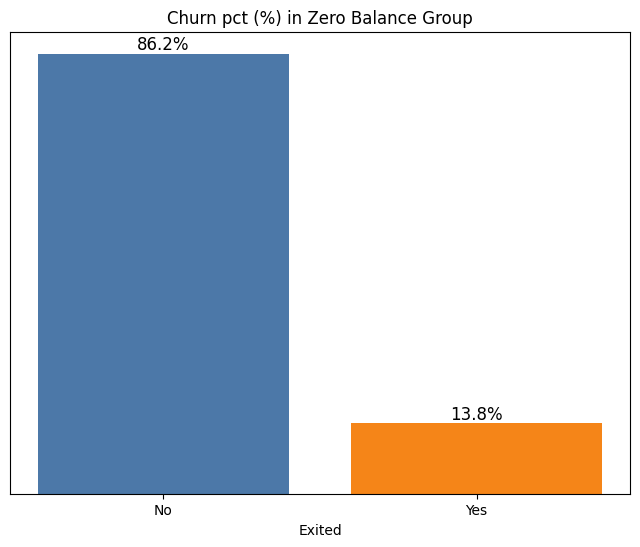

In [23]:
churn_zero_balance = zero_balance.groupby('Exited_label', observed= False).agg(customer_count= ('CustomerId', 'count')).reset_index()
churn_zero_balance['Churn_pct (%)'] = ((churn_zero_balance['customer_count'] * 100)/ zero_balance['CustomerId'].count()).round(2)
print(churn_zero_balance)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_yticks([])
ax.bar( data=churn_zero_balance, x="Exited_label",height="Churn_pct (%)", color= ['#4C78A8','#F58518'])
ax.set_title('Churn pct (%) in Zero Balance Group')
ax.set_xlabel('Exited')

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=12)

The zero-balance group has a churn rate of 13.8%.

  Exited_label  customer_count  Churn_pct (%)
0           No            4845           75.9
1          Yes            1538           24.1


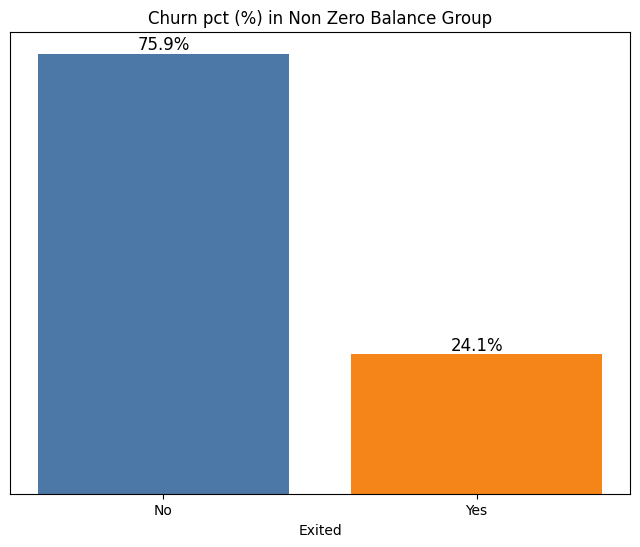

In [24]:
churn_non_zero_balance = non_zero_balance.groupby(
    'Exited_label', observed= False
    ).agg(
        customer_count= ('CustomerId', 'count')
        ).reset_index()

churn_non_zero_balance['Churn_pct (%)'] = (
    (churn_non_zero_balance['customer_count'] * 100 )/ non_zero_balance['CustomerId'].count()
    ).round(2)
    
print(churn_non_zero_balance)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_yticks([])
ax.bar( data=churn_non_zero_balance, x="Exited_label",height="Churn_pct (%)", color= ['#4C78A8','#F58518'])
ax.set_title('Churn pct (%) in Non Zero Balance Group')
ax.set_xlabel('Exited')

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=12)

24.1% for customers with a non-zero balance.

  Exited_label  customer_count  Churn_pct (%)
0           No            7962          79.62
1          Yes            2038          20.38


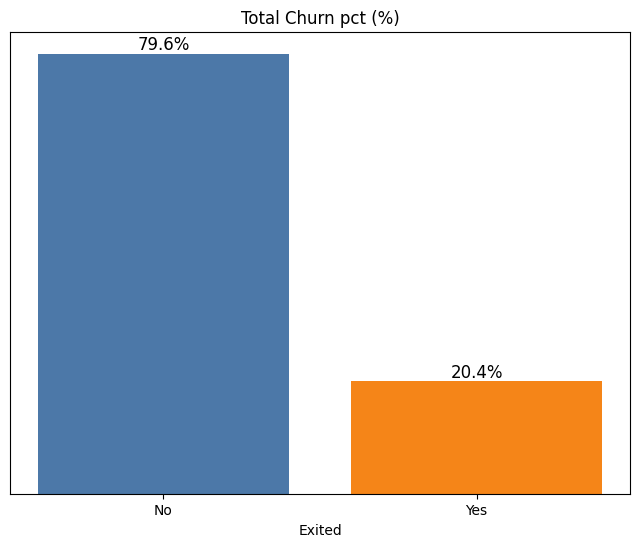

In [25]:
total_churn = data.groupby('Exited_label', observed= False).agg(customer_count= ('CustomerId', 'count')).reset_index()
total_churn['Churn_pct (%)'] = ((total_churn['customer_count'] * 100) /data['CustomerId'].count()).round(2)
print(total_churn)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_yticks([])
ax.bar( data=total_churn, x="Exited_label",height="Churn_pct (%)", color= ['#4C78A8','#F58518'])
ax.set_title('Total Churn pct (%)')
ax.set_xlabel('Exited')

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=12)

Overall, 20% of customers have churned.

Table with Tenure_range by Gender:
  Tenure_range  Gender  customer_count  Churn  Churn_pct (%)
0          0-3  Female            1631    417          25.57
1          0-3    Male            1874    324          17.29
2          3-5  Female             890    231          25.96
3          3-5    Male            1111    181          16.29
4          5-7  Female             922    206          22.34
5          5-7    Male            1073    167          15.56
6           7+  Female            1100    285          25.91
7           7+    Male            1399    227          16.23
Table with EstimatedSalary_bin by Gender:
  EstimatedSalary_bin  Gender  customer_count  Churn  Churn_pct (%)
0               0-50K  Female            1133    277          24.45
1               0-50K    Male            1367    223          16.31
2            50K-100K  Female            1090    264          24.22
3            50K-100K    Male            1410    231          16.38
4           100K-150K  Female     

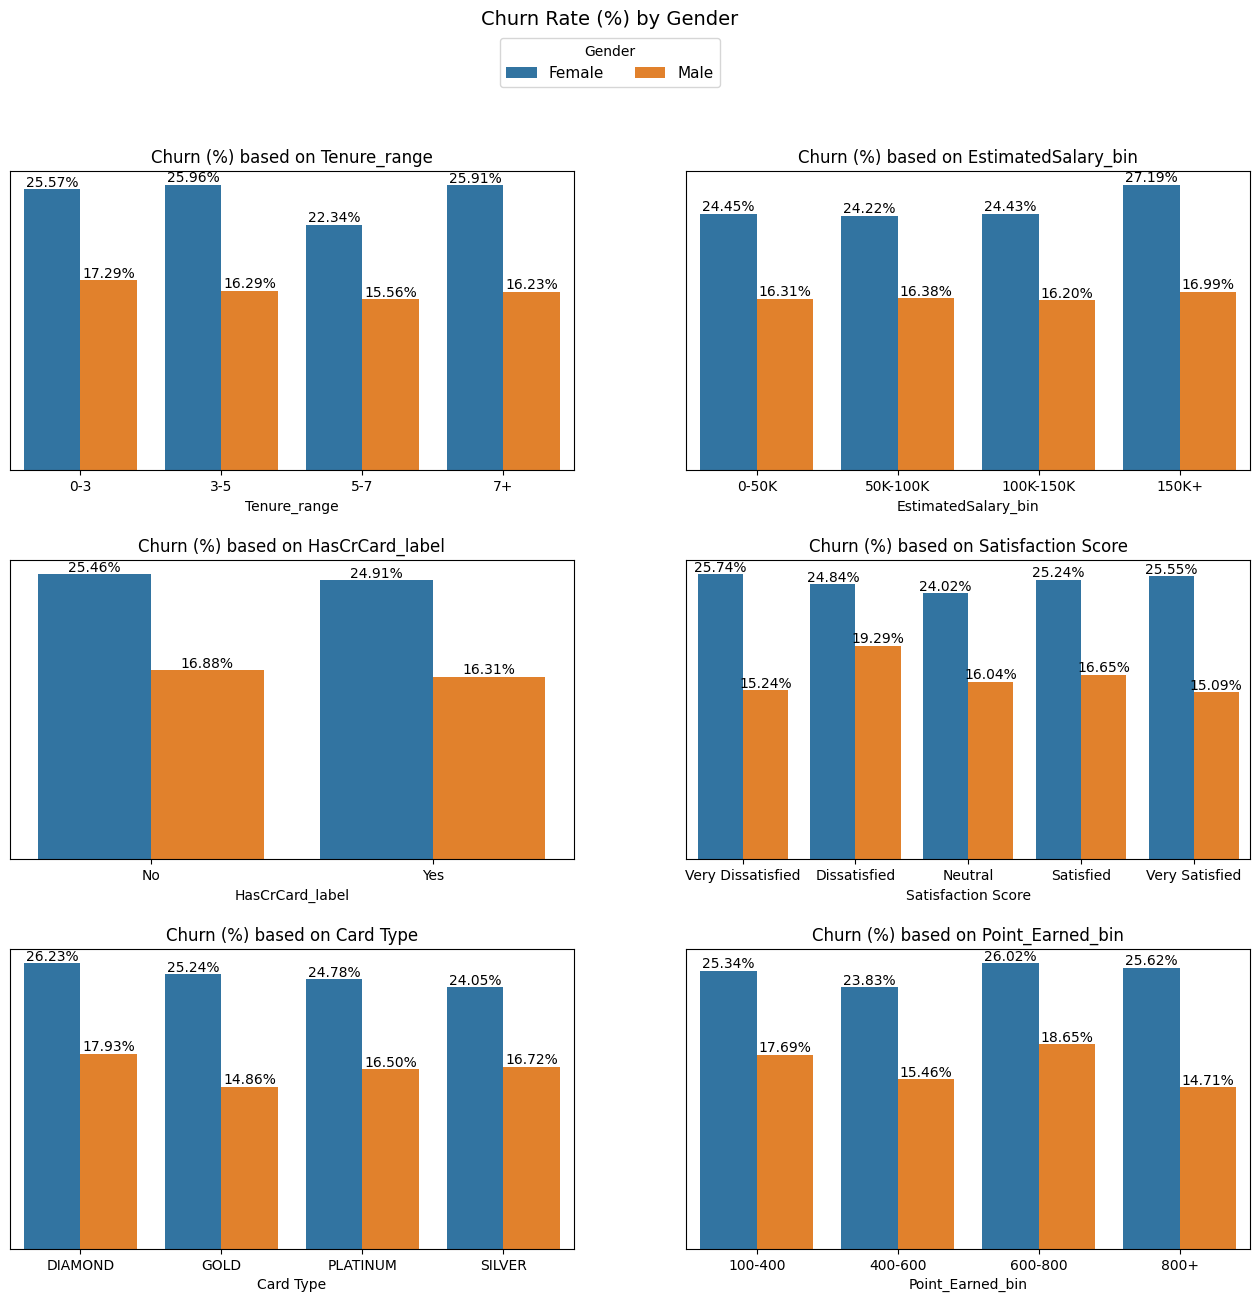

In [26]:
cols_to_plot = ['Tenure_range', 'EstimatedSalary_bin', 'HasCrCard_label', 
                'Satisfaction Score', 'Card Type', 'Point_Earned_bin']

col = 2
row = math.ceil(len(cols_to_plot) / col)

fig, ax = plt.subplots(row, col, figsize=(16, 14))
ax_flat = ax.flatten()
fig.suptitle('Churn Rate (%) by Gender', fontsize=14, y=0.995)
fig.subplots_adjust(hspace=0.3)

for i, feature in enumerate(cols_to_plot):
    x = data.groupby([feature, 'Gender'], observed=False).agg(
        customer_count=('CustomerId', 'count'),
        Churn=('Exited', 'sum')
    ).reset_index()
    x['Churn_pct (%)'] = ((x['Churn'] * 100) / x['customer_count']).round(2)

    ax_flat[i].set_title(f'Churn (%) based on {feature}')
    ax_flat[i].set_yticks([])
    sns.barplot(data=x, x=feature, y='Churn_pct (%)', hue='Gender', ax=ax_flat[i])
    for container in ax_flat[i].containers:
        ax_flat[i].bar_label(container, fmt='%1.2f%%', label_type='edge', fontsize=10)

    print(f'Table with {feature} by Gender:\n{x}')

for j in range(len(cols_to_plot), len(ax_flat)):
    fig.delaxes(ax_flat[j])

for ax_item in ax_flat:
    legend = ax_item.get_legend()
    if legend is not None:
        legend.remove()

handles, labels = ax_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.98), 
           ncol=2, frameon=True, fontsize=11, title='Gender')

Across tenure, card type, satisfaction score, Credit Card Ownership and point Earned, churn stays close to the overall rate. The consistent gap is gender, with women churning more.

Table with Tenure_range vs NumOfProducts:
   Tenure_range  NumOfProducts  customer_count  Churn  Churn_pct (%)
0           0-3              1            1806    511          28.29
1           0-3              2            1575    123           7.81
2           0-3              3             101     84          83.17
3           0-3              4              23     23         100.00
4           3-5              1            1005    289          28.76
5           3-5              2             930     69           7.42
6           3-5              3              56     44          78.57
7           3-5              4              10     10         100.00
8           5-7              1            1007    258          25.62
9           5-7              2             938     71           7.57
10          5-7              3              41     35          85.37
11          5-7              4               9      9         100.00
12           7+              1            1266    351        

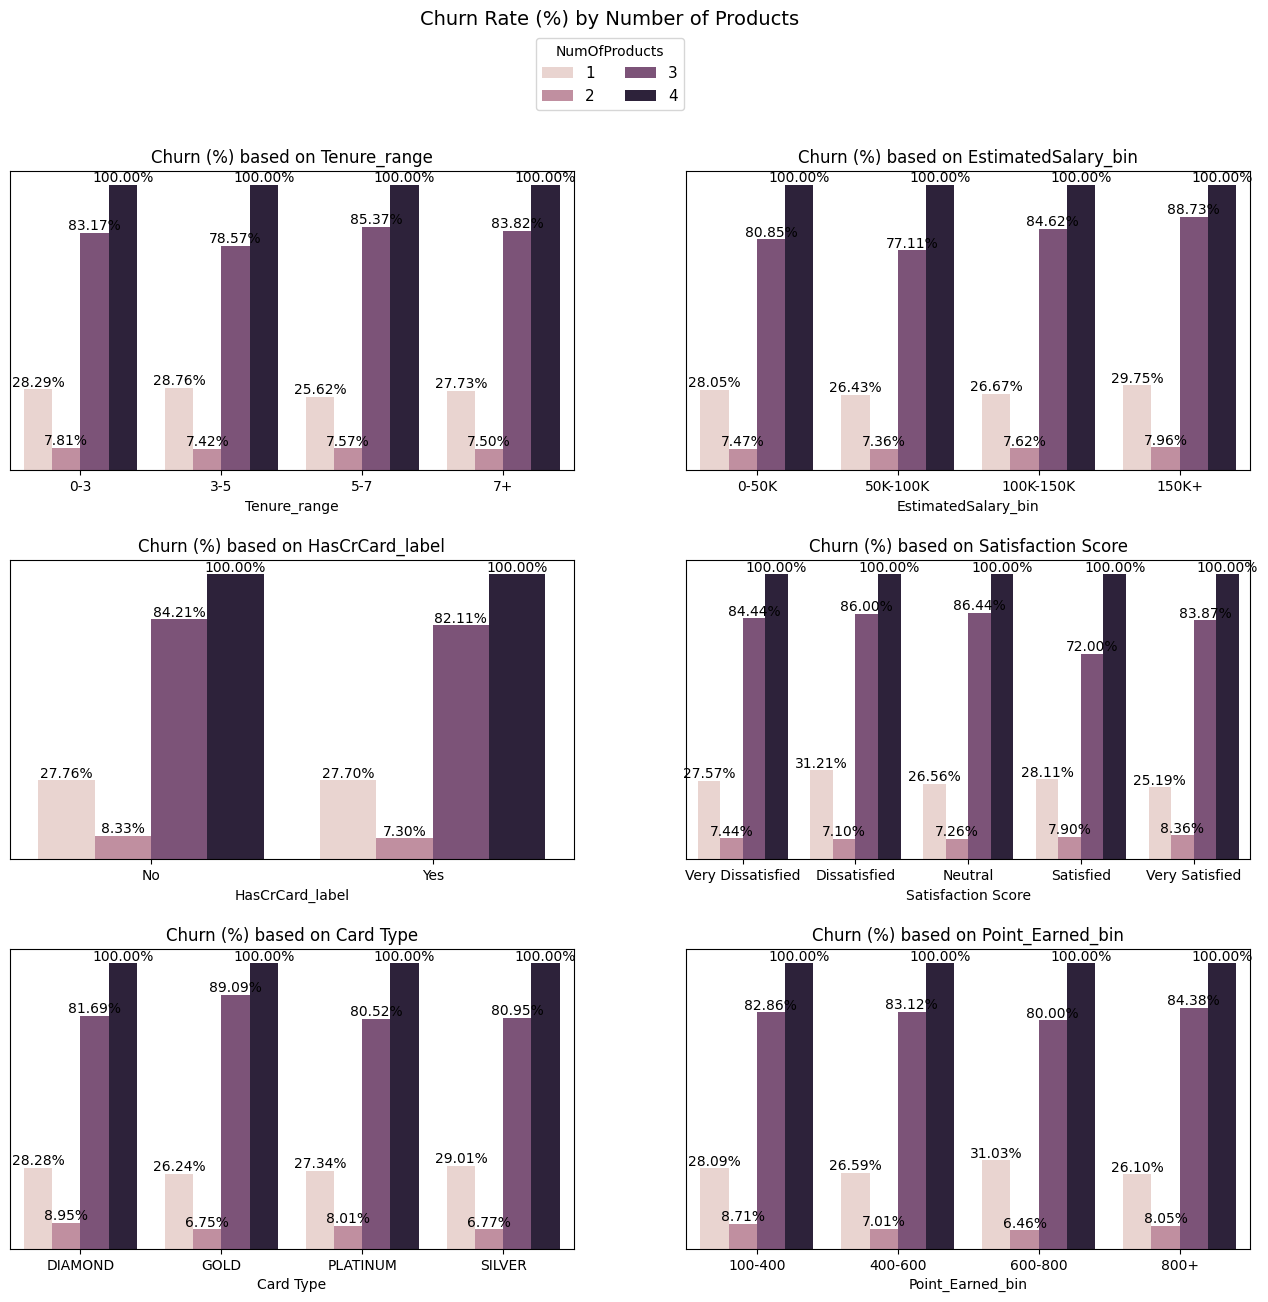

In [27]:
fig, ax = plt.subplots(row, col, figsize=(16, 14))
ax_flat = ax.flatten()
fig.suptitle('Churn Rate (%) by Number of Products', fontsize=14, y=0.995)
fig.subplots_adjust(hspace=0.3)

for i, feature in enumerate(cols_to_plot):
    y = data.groupby([feature, 'NumOfProducts'], observed=False).agg(
        customer_count=('CustomerId', 'count'),
        Churn=('Exited', 'sum')
    ).reset_index()
    y['Churn_pct (%)'] = ((y['Churn'] * 100) / y['customer_count']).round(2)

    ax_flat[i].set_title(f'Churn (%) based on {feature}')
    ax_flat[i].set_yticks([])
    sns.barplot(data=y, x=feature, y='Churn_pct (%)', hue='NumOfProducts', ax=ax_flat[i])
    for container in ax_flat[i].containers:
        ax_flat[i].bar_label(container, fmt='%1.2f%%', label_type='edge', fontsize=10)

    print(f'Table with {feature} vs NumOfProducts:\n{y}\n')

for j in range(len(cols_to_plot), len(ax_flat)):
    fig.delaxes(ax_flat[j])

for ax_item in ax_flat:
    legend = ax_item.get_legend()
    if legend is not None:
        legend.remove()


handles, labels = ax_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.98), 
           ncol=2, frameon=True, fontsize=11, title='NumOfProducts')

- Across features like `Tenure_range`, `EstimatedSalary_bin`, `HasCrCard`,`Satisfaction Score`, `Card Type`,`Point_Earned_bin`.All share similar pattern, 2 Product have lowest churn rate, 3+ Jumped sharply.

### Key Summary and Insights

- Overall, approximately **20%** of customers have churned. Churn is lower among customers with a zero balance (**13.8%**) than among those with a non-zero balance (**24.1%**).
- **Germany has the highest churn rate** among the three countries, and female customers have higher churn rates than male customers across all three.
- **Product count is strongly associated with churn:** customers with 3 or 4 products tend to have higher churn, while those with 2 products generally have the lowest churn. Groups with 4 products show 100% churn, so interpret those rates alongside group sizes.
- **Age and tenure patterns vary by segment.** Customers aged 45 and older tend to have higher churn, while longer-tenured zero-balance customers tend to churn less than newer ones.
- Active membership is associated with lower churn. Credit-card ownership, tenure,salary, satisfaction, card type and points earned show no meaningful difference. The consistent gap is gender, with women churning more.
- The _Complain_ feature is perfectly correlated with _Exited_, which may indicate target leakage; exclude it from predictive modeling unless its timing confirms it is available before churn.

## Recommendations:
- Review how the bank sells 3rd or 4th product, since churn is very high.
- Run retention outreach for inactive customers and customers aged 45+.
- Look at why German customers churn more.
- Study what customers with 2 products have in common, because they have the least churn rate.
